# TP 1 — Mise en route : charger, vérifier, regarder

_Cours EPD-GIT-5534 — Introduction au ML pour l'exploitation d'infrastructures — Séance 1._

**Objectifs :** charger et auditer `nosys_metriques.csv`, produire la vue journalière de srv-01, le tableau de classement par serveur, le profil horaire et 5 constats chiffrés.

**Durée :** 2 h 20 (B1 30 min, B2 20 min, B3 30 min, B4 40 min, B5 20 min). Graine 5534.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RNG = np.random.default_rng(5534)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.4.6 | pandas 3.0.6


## B1 — Charger et vérifier (30 min)

**Objectifs :** charger `nosys_metriques.csv` avec les bons types, vérifier la forme (69 120 lignes = 8 serveurs × 30 j × 288 fenêtres), la constance du pas de 5 min et l'absence de valeurs manquantes. Pièges : oublier `parse_dates`, travailler dans le mauvais répertoire.

In [2]:
m = pd.read_csv("data/nosys_metriques.csv", parse_dates=["horodatage"])
print("shape :", m.shape)                       # attendu (69120, 10)
print("serveurs :", sorted(m["serveur"].unique()))
print("période :", m["horodatage"].min(), "->", m["horodatage"].max())
print()
print("pas d'échantillonnage (les 5 plus fréquents) :")
print(m["horodatage"].diff().value_counts().head())
print()
print("valeurs manquantes par colonne :")
print(m.isna().sum())

shape : (69120, 10)
serveurs : ['srv-01', 'srv-02', 'srv-03', 'srv-04', 'srv-05', 'srv-06', 'srv-07', 'srv-08']
période : 2026-09-01 00:00:00 -> 2026-09-30 23:55:00

pas d'échantillonnage (les 5 plus fréquents) :
horodatage
0 days 00:05:00       69112
-30 days +00:05:00        7
Name: count, dtype: int64

valeurs manquantes par colonne :
horodatage            0
serveur               0
cpu_pct               0
ram_pct               0
latence_ms            0
paquets_perdus_pct    0
temperature_c         0
conso_kwh             0
capacite_cpu          0
alarme                0
dtype: int64


**Attendu :** shape `(69120, 10)`, 8 serveurs, pas constant de 300 s (sauf le premier point, `NaT`), 0 valeur manquante partout.

## B2 — Inventaire de qualité (20 min)

Pour chaque colonne : type, plage min/max, manquants. Puis complétude (8 640 fenêtres par serveur) et plausibilité physique (`0 ≤ cpu_pct ≤ 100`, `ram_pct` dans [0, 100], température > 20 °C).

In [3]:
inventaire = pd.DataFrame({
    "type": m.dtypes.astype(str),
    "min": m.select_dtypes("number").min(),
    "max": m.select_dtypes("number").max(),
    "manquants": m.isna().sum()})
print(inventaire)
print()
print("fenêtres par serveur :")
print(m.groupby("serveur").size())
assert (m.groupby("serveur").size() == 8640).all(), "complétude rompue"
print()
print("plausibilité : CPU %.1f..%.1f %%, RAM %.1f..%.1f %%, temp %.1f..%.1f °C"
      % (m["cpu_pct"].min(), m["cpu_pct"].max(),
         m["ram_pct"].min(), m["ram_pct"].max(),
         m["temperature_c"].min(), m["temperature_c"].max()))
print("=> 0 valeur manquante, bornes physiques respectées : dataset propre.")

                              type        min         max  manquants
alarme                       int64   0.000000    1.000000          0
capacite_cpu               float64   0.704888    0.985416          0
conso_kwh                  float64   0.934000    3.629000          0
cpu_pct                    float64   2.000000   95.990000          0
horodatage          datetime64[us]        NaN         NaN          0
latence_ms                 float64   8.540000  156.080000          0
paquets_perdus_pct         float64   0.021000    1.314000          0
ram_pct                    float64  24.630000   84.380000          0
serveur                        str        NaN         NaN          0
temperature_c              float64  24.420000   42.650000          0

fenêtres par serveur :
serveur
srv-01    8640
srv-02    8640
srv-03    8640
srv-04    8640
srv-05    8640
srv-06    8640
srv-07    8640
srv-08    8640
dtype: int64

plausibilité : CPU 2.0..96.0 %, RAM 24.6..84.4 %, temp 24.4..42.6 °C
=> 0 v

**Réponse attendue :** 0 valeur manquante ; CPU max 96.0 % ; température max 42.6 °C : tout est plausible — dit avec la preuve.

## B3 — Visualiser srv-01 sur 30 jours (30 min)

Vue journalière (3 sous-graphiques : CPU, latence, alarmes) puis réponse aux questions : où sont les 2 incidents de srv-01 ? Un seuil fixe « CPU > 90 % » les aurait-il détectés ? La latence monte-t-elle avec le CPU ?

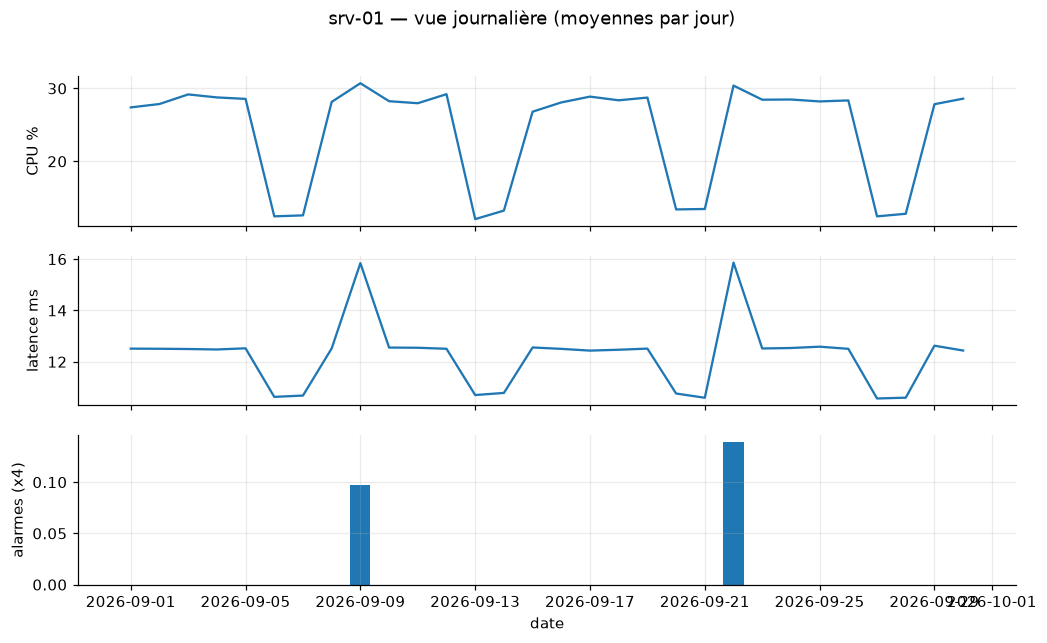

fenêtres d'alarme srv-01 : ['09/09 14h', '22/09 03h']
CPU moyen pendant alarme : 94.0 % vs hors alarme : 24.2 %


In [4]:
s1 = m[m["serveur"] == "srv-01"]
jour = (s1.set_index("horodatage").drop(columns=["serveur"])
          .resample("D").mean())            # 30 lignes, une par jour

fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
ax[0].plot(jour.index, jour["cpu_pct"]);  ax[0].set_ylabel("CPU %")
ax[1].plot(jour.index, jour["latence_ms"]); ax[1].set_ylabel("latence ms")
ax[2].bar(jour.index, jour["alarme"] * 4, width=0.7)  # fenêtres x4 visibles
ax[2].set_ylabel("alarmes (x4)")
ax[2].set_xlabel("date")
fig.suptitle("srv-01 — vue journalière (moyennes par jour)")
plt.show()

jours_alarme = s1.loc[s1["alarme"] == 1, "horodatage"].dt.strftime("%d/%m %Hh")
print("fenêtres d'alarme srv-01 :", sorted(jours_alarme.unique()))
print("CPU moyen pendant alarme : %.1f %% vs hors alarme : %.1f %%"
      % (s1.loc[s1["alarme"] == 1, "cpu_pct"].mean(),
         s1.loc[s1["alarme"] == 0, "cpu_pct"].mean()))

**Lecture :** les 2 incidents de srv-01 tombent le 9/09 vers 14 h et le 22/09 vers 3 h, comme sur tout le parc. Le CPU y reste sous 90 % : un seuil fixe ne les aurait **pas** détectés. CPU et latence montent ensemble (corrélation hors incidents ≈ 0.8).

## B4 — Statistiques par serveur (40 min)

Tableau de classement (`cpu_moy`, `cpu_max`, `lat_p99`, `temp_max`, alarmes, conso kWh ×5/60, capacité), ratio d'utilisation effective `cpu_moy / (capacite × 100)`, consommation totale du parc.

In [5]:
par_srv = (m.groupby("serveur")
             .agg(cpu_moy=("cpu_pct", "mean"),
                  cpu_max=("cpu_pct", "max"),
                  lat_p99=("latence_ms", lambda s: s.quantile(0.99)),
                  temp_max=("temperature_c", "max"),
                  alarmes=("alarme", "sum"),
                  conso_kwh_tot=("conso_kwh", lambda s: s.sum() * 5 / 60),
                  capacite=("capacite_cpu", "first")))
par_srv["ratio_capacite"] = par_srv["cpu_moy"] / (par_srv["capacite"] * 100)
print(par_srv.sort_values("cpu_moy", ascending=False).round(2))
print()
print("consommation totale du parc : %.0f kWh" % par_srv["conso_kwh_tot"].sum())
print("ratio capacite max :", par_srv["ratio_capacite"].idxmax(),
      "-> %.3f" % par_srv["ratio_capacite"].max())

         cpu_moy  cpu_max  lat_p99  temp_max  alarmes  conso_kwh_tot  \
serveur                                                                
srv-05     24.56    95.57    16.38     42.65       17        1584.54   
srv-01     24.33    95.99    16.24     42.43       17        1577.19   
srv-06     24.06    95.95    16.35     41.83       17        1567.29   
srv-08     20.11    95.92    16.31     40.32       17        1438.53   
srv-07     19.64    95.87    16.19     39.59       17        1424.09   
srv-04     18.91    95.87    16.30     39.64       17        1402.02   
srv-03     17.97    95.90    16.43     39.64       17        1368.18   
srv-02     14.37    95.94    16.28     37.79       17        1252.33   

         capacite  ratio_capacite  
serveur                            
srv-05       0.70            0.35  
srv-01       0.83            0.29  
srv-06       0.92            0.26  
srv-08       0.99            0.20  
srv-07       0.76            0.26  
srv-04       0.87          

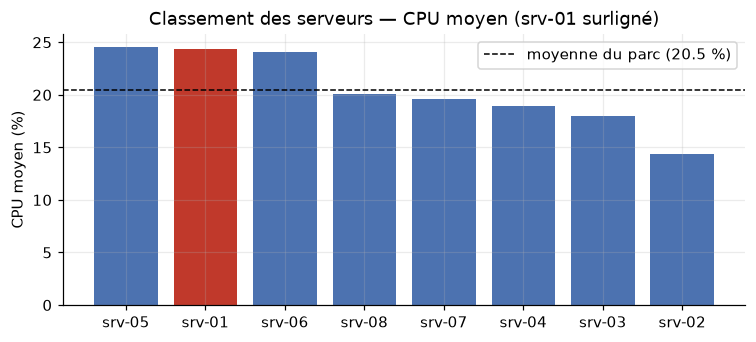

In [6]:
ordre = par_srv.sort_values("cpu_moy", ascending=False)
cpu_parc = float(m["cpu_pct"].mean())
fig, ax = plt.subplots(figsize=(8, 3.2))
cols = ["#c0392b" if s == "srv-01" else "#4c72b0" for s in ordre.index]
ax.bar(ordre.index, ordre["cpu_moy"], color=cols)
ax.axhline(cpu_parc, color="k", ls="--", lw=1,
           label="moyenne du parc (%.1f %%)" % cpu_parc)
ax.set_ylabel("CPU moyen (%)")
ax.set_title("Classement des serveurs — CPU moyen (srv-01 surligné)")
ax.legend(); plt.show()

## Bonus — le facteur jour/nuit

CPU moyen par heure pour srv-01 : vérifier le facteur jour/nuit × 3 annoncé en cours.

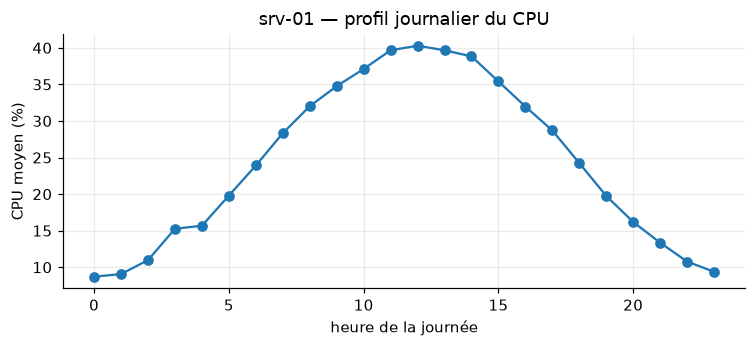

facteur jour/nuit mesuré : x2.6


In [7]:
par_heure = s1.groupby(s1["horodatage"].dt.hour)["cpu_pct"].mean()
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(par_heure.index, par_heure.values, marker="o")
ax.set_xlabel("heure de la journée"); ax.set_ylabel("CPU moyen (%)")
ax.set_title("srv-01 — profil journalier du CPU")
plt.show()
facteur = par_heure[8:20].mean() / par_heure[[0, 1, 2, 3, 4, 5, 23]].mean()
print("facteur jour/nuit mesuré : x%.1f" % facteur)

## B5 — Livrable : la fiche « état des lieux » (20 min)

**5 constats chiffrés** (chiffre + référence + interprétation), **3 risques pour le SLA** reliés aux données, **1 recommandation** d'automatisation. Barème : constats 10 pts, risques 5 pts, notebook exécutable et reproductible 5 pts.

### Constats chiffrés (mesurés sur les données du dossier)

1. Le parc est globalement sain : CPU moyen **20.5 %**, p99 de latence **16.3 ms** pour un SLO à 100 ms (marge ×6.1) ; hors incidents le p99 vaut 16.2 ms.
2. Mais la disponibilité calculée est **99.8 %** < SLA 99,9 % : **11.3 h** d'indisponibilité cumulée sur le mois.
3. Les 16 incidents suivent **2 créneaux communs** à tous les serveurs (09/09 à 14h et 22/09 à 03h) : cause partagée probable (batch, déploiement), pas 16 pannes indépendantes.
4. Corrélation latence–CPU **0.8** hors incidents : la charge explique la latence normale — utile pour la prévision de la séance 4 ; pendant incident le CPU vaut ×4.6 la normale.
5. Consommation totale : **11614 kWh**/mois ; srv-05 et srv-01 en tête ; le serveur le plus « tassé » relativement à sa capacité est **srv-01** (ratio 0.29, capacité 0,83).

### Risques SLA

- Incidents synchrones entre serveurs (cause commune) → une seule cause peut faire tomber les 8 SLA à la fois.
- CPU ×4.6 pendant incident → marge de capacité faible sur srv-01 (ratio 0.29).
- Corrélation latence–CPU 0.8 → un pic de charge prévisible donne une latence prévisible : à modéliser (séance 4).

### Recommandation

Automatiser la **détection précoce** : le seuil fixe CPU > 90 % ne voit aucun incident ; un modèle supervisé sur fenêtres de 10 min (séances 2–3) apprend la signature pré-incident en respectant un budget d'alertes. Reproductibilité : graine 5534, données `data/nosys_metriques.csv`.